# **Preparing Dependancies**

In [1]:
!pip install -q diffusers transformers accelerate torch safetensors matplotlib

# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

In [2]:
import torch
from diffusers import (
    StableDiffusionPipeline,
    StableDiffusionInpaintPipeline,
    StableDiffusionImg2ImgPipeline,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
    DDIMScheduler,
)
from PIL import Image, ImageDraw, ImageFilter
import matplotlib.pyplot as plt
import numpy as np

# Load Stable Diffusion v1.5
model_id = "runwayml/stable-diffusion-v1-5"
device = "cuda" if torch.cuda.is_available() else "cpu"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    safety_checker=None,
).to(device)

print(f"Model loaded on {device}")

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Model loaded on cuda


## **Generate Image**

  0%|          | 0/50 [00:00<?, ?it/s]

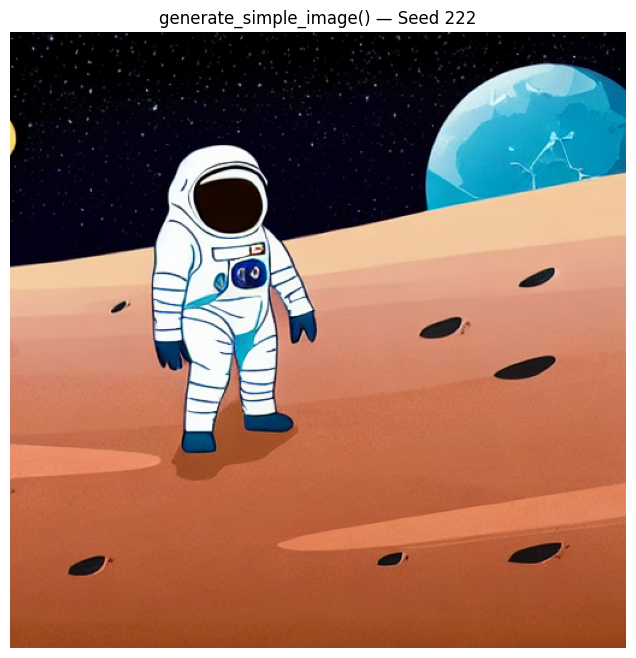

In [3]:
def generate_simple_image(prompt, negative_prompt, seed):
    """
    Generate gambar menggunakan Stable Diffusion Pipeline.
    Parameter: prompt, negative_prompt, seed.
    """
    generator = torch.Generator(device).manual_seed(seed)

    image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
    ).images[0]

    return image


# Konfigurasi
prompt = "an astronaut standing on the moon surface, planet earth and stars visible in the background, digital illustration, clean character illustration style, trending on ArtStation, flat 2d, highly detailed, sharp focus, soft natural lighting, vibrant colors"
negative_prompt = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
seed = 222

# Generate
simple_image = generate_simple_image(
    prompt, negative_prompt, seed,
)
# Tampilkan
plt.figure(figsize=(8, 8))
plt.imshow(simple_image)
plt.title("generate_simple_image() — Seed 222")
plt.axis("off")
plt.show()

## **Generate Image with Hyperparameter Configuration**

  0%|          | 0/90 [00:00<?, ?it/s]

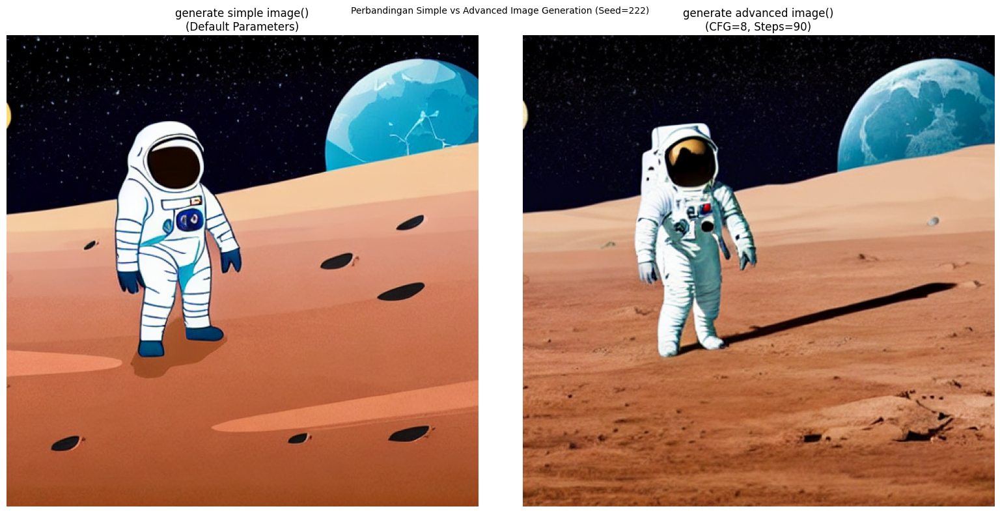

In [4]:
def generate_advanced_image(prompt, negative_prompt, seed, guidance_scale, num_inference_steps):
    """
    Generate gambar dengan kontrol hyperparameter tambahan.
    Parameter: prompt, negative_prompt, seed, guidance_scale, num_inference_steps.
    """
    generator = torch.Generator(device).manual_seed(seed)

    image = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps,
    ).images[0]

    return image


# Konfigurasi (prompt & negative_prompt IDENTIK dengan generate_simple_image)

prompt = "an astronaut standing on the moon surface, planet earth and stars visible in the background, digital illustration, flat 2d, highly detailed, soft natural lighting, vibrant colors"
negative_prompt = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
seed = 222

# Generate dengan hyperparameter
advanced_image = generate_advanced_image(
    prompt, negative_prompt, seed,
    guidance_scale=8.0,
    num_inference_steps=90
)

# Tampilkan perbandingan
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(simple_image)
axes[0].set_title("generate simple image()\n(Default Parameters)")
axes[0].axis("off")

axes[1].imshow(advanced_image)
axes[1].set_title("generate advanced image()\n(CFG=8, Steps=90)")
axes[1].axis("off")

plt.suptitle("Perbandingan Simple vs Advanced Image Generation (Seed=222)", fontsize=10)
plt.tight_layout()
plt.show()

## **Guidance Scale Comparison**

  0%|          | 0/30 [00:00<?, ?it/s]

✅ Generated with Guidance Scale = 1.0


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Generated with Guidance Scale = 4.0


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Generated with Guidance Scale = 7.5


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Generated with Guidance Scale = 10.0


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Generated with Guidance Scale = 12.0


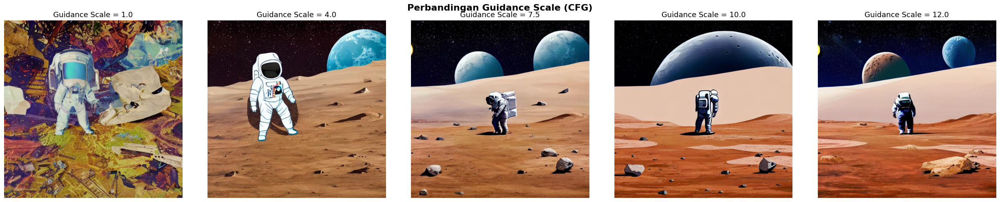

In [5]:
# Eksperimen Guidance Scale
guidance_scales = [1.0, 4.0, 7.5, 10.0, 12.0]
guidance_images = []

prompt = "an astronaut standing on the moon surface, planet earth and stars visible in the background, digital illustration, flat 2d, highly detailed, soft natural lighting, vibrant colors"
negative_prompt = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
seed = 222

for cfg in guidance_scales:
    img = generate_advanced_image(prompt, negative_prompt, seed, guidance_scale=cfg, num_inference_steps=30)
    guidance_images.append(img)
    print(f"✅ Generated with Guidance Scale = {cfg}")

# Tampilkan grid 2x2
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for idx, (img, cfg) in enumerate(zip(guidance_images, guidance_scales)):
    axes[idx].imshow(img)
    axes[idx].set_title(f"Guidance Scale = {cfg}", fontsize=13)
    axes[idx].axis("off")

plt.suptitle("Perbandingan Guidance Scale (CFG)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### **Guidance Scale Explanation:**

*   **Gambar dengan "Scale" Rendah (1.0, 4.0, dan 7.5-normal):**
Pada gambar dengan skala 2.5 dan 5.0 menunjukkan nilai yang rendah dalam parameter CGP, skala menunjukkan bahwa ai memiliki kebebasan untuk berimajinasi dan bereksperimen dengan objek yang tidak saya minta. Hasilnya, gambar dengan skala 1.0 menjadi bebas, tidak sesuai dengan prompt yang diberikan, bahkan ada saja objek yang ditambahkan seperti perpaduan warna yang tidak diminta. Di gambar dengan skala 4.0 gambar jadi lebih terarah, ada astronot yang berdiri di permukaan bulan, dan bumi sebagai latar belakang namun, masih kurang detail seperti gambar dengan skala 7.5. Normalnya, CGP bernilai 7.5, bisa dilihat di gambar ini astronot berdiiri dipermukaan yang jauh lebih bertekstur dan jauh lebih 8k.

*   **Gambar dengan "Scale" Tinggi (10 dan 12.0):**
Digambar dengan skala 10.0 dan 12.0 AI terus improve penambahan detailing visual. Di gambar dengan skala 10.0, AI mengubah struktur pada bumi dan menambah bayangan dari astronot. Disini mulai terlihat bahwa AI sudah menunjukkan perubahan naturalitas (bisa dilihat di bentuk bayangan). Sedangkan di skala 12.0, gambar sudah hilang naturalitasnya, kontras dan saturasi jadi jauh lebih tinggi dan berlebihan dibanding sebelumnya. Alhasil gambar dengan skala yang terlalu tinggi menjadikan gambar jadi tidak berkualitas.

## **Inference Steps Comparison**

  0%|          | 0/5 [00:00<?, ?it/s]

✅ Generated with Inference Steps = 5


  0%|          | 0/10 [00:00<?, ?it/s]

✅ Generated with Inference Steps = 10


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Generated with Inference Steps = 30


  0%|          | 0/50 [00:00<?, ?it/s]

✅ Generated with Inference Steps = 50


  0%|          | 0/100 [00:00<?, ?it/s]

✅ Generated with Inference Steps = 100


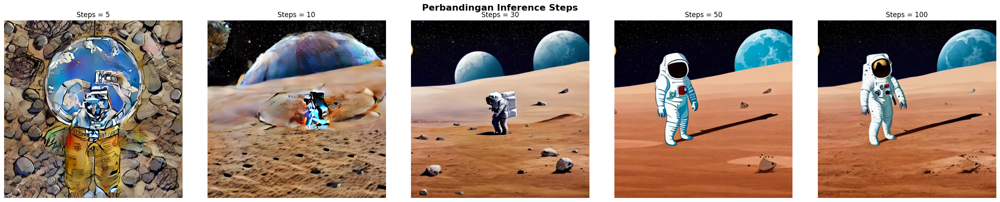

In [6]:
# Eksperimen Inference Steps
inference_steps = [5, 10, 30, 50, 100]
steps_images = []

prompt = "an astronaut standing on the moon surface, planet earth and stars visible in the background, digital illustration, flat 2d, highly detailed, soft natural lighting, vibrant colors"
negative_prompt = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
seed = 222

for steps in inference_steps:
    img = generate_advanced_image(prompt, negative_prompt, seed, guidance_scale=7.5, num_inference_steps=steps)
    steps_images.append(img)
    print(f"✅ Generated with Inference Steps = {steps}")

# Tampilkan grid
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for idx, (img, step) in enumerate(zip(steps_images, inference_steps)):
    axes[idx].imshow(img)
    axes[idx].set_title(f"Steps = {step}", fontsize=12)
    axes[idx].axis("off")

plt.suptitle("Perbandingan Inference Steps", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### **Inference Step Explanation:**

*   **Gambar dengan "Step" Rendah (5 dan 10):**
Gambar dengan step 5 menunjukkan penggunaan nilai yang rendah terhadap steps, hal ini menghasilkan gambar yang tidak jelas dan belum selesai, yang terlihat hanya warna coklat sebagai background, dan objek putih kebiruan ditengah yang masih belum teridentifikasi gambar apa. Sedangkan pada gambar dengan step 10, gambar sudah mulai terbentuk, samar-samar sudah ada astronot ditengah. Hanya saja, masih ada bagian pada gambar yang belum selesai. Dari kedua gambar kita bisa lihat bahwa jika kita menggunakan parameter inference step yang rendah maka akan menghasilkan gambar yang belum jadi dan cenderung blur.

*   **Gambar dengan "Step" Tinggi (30, 50, dan 100):**
Gambar dengan step 30 dan 50 menunjukkan penggunaan nilai yang tinggi terhadap parameter steps. Gambar dengan steps 30 memperlihatkan gambar yang sudah sepenuhnya selesai, terlihat detail nya, halus, dan stabil secara visual. Astronot sudah terlihat dengan jelas, dan bisa dibedakan mana permukaan bulan dan mana bumi sebagai latar. Dibandingkan dengan gambar dengan step 50, gambar jadi jauh lebih detail dan lebih halus, dengan penggunaan warna yang lebih konsisten. Kemudian, hasil dari pantulan cahaya astronot juga jauh lebih jelas dibanging gambar dengan step 30. Begitupun di steps 100, gambar jauh lebih detail lagi namun, waktu yang dibutuhkan juga akan jadi semakin lama.


## **Batch Inference from One Prompt**

  0%|          | 0/30 [00:00<?, ?it/s]

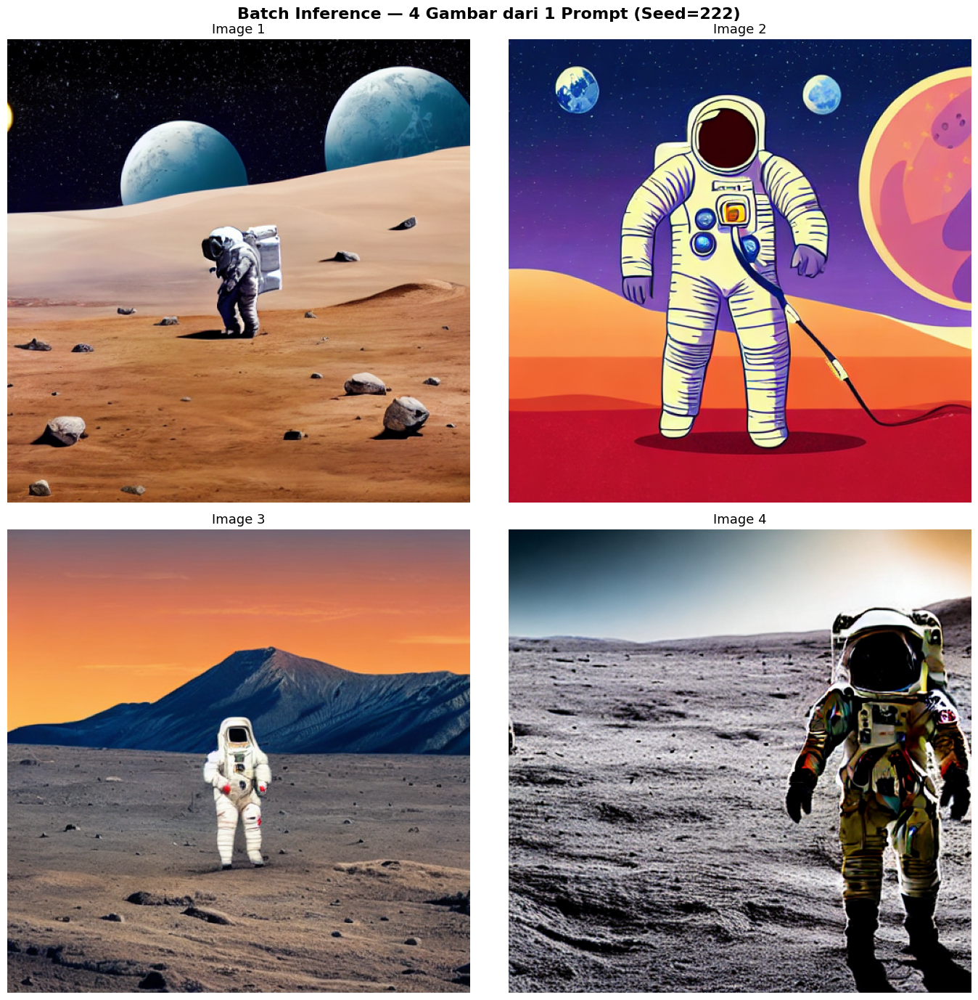

In [7]:
def generate_batch_images(prompt, negative_prompt, seed, guidance_scale=7.5, num_inference_steps=30, num_images=4):
    """
    Generate beberapa gambar sekaligus dari satu prompt (batch inference).
    """
    generator = torch.Generator(device).manual_seed(seed)

    images = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps,
        num_images_per_prompt=num_images,
    ).images

    return images


# Konfigurasi
prompt = "an astronaut standing on the moon surface, planet earth and stars visible in the background, digital illustration, flat 2d, highly detailed, soft natural lighting, vibrant colors"
negative_prompt = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
seed = 222

# Generate batch 4 gambar
batch_images = generate_batch_images(prompt, negative_prompt, seed, num_images=4)

# Tampilkan grid 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for idx, img in enumerate(batch_images):
    ax = axes[idx // 2][idx % 2]
    ax.imshow(img)
    ax.set_title(f"Image {idx + 1}", fontsize=13)
    ax.axis("off")

plt.suptitle("Batch Inference — 4 Gambar dari 1 Prompt (Seed=222)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

## **Load Scheduler**

  0%|          | 0/30 [00:00<?, ?it/s]

✅ Generated with scheduler: Euler A


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Generated with scheduler: DPM++


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Generated with scheduler: DDIM


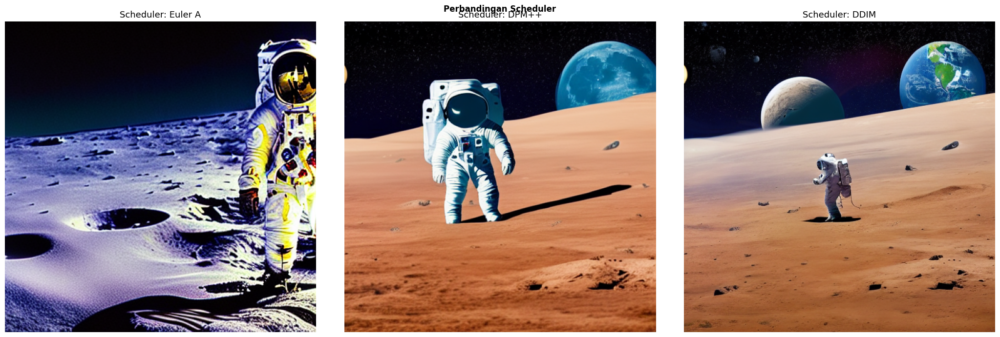

In [8]:
def load_scheduler(pipe, scheduler_name):
    if scheduler_name == "Euler A":
        pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
    elif scheduler_name == "DPM++":
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    elif scheduler_name == "DDIM":
        pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
    else:
        print(f"Scheduler '{scheduler_name}' tidak dikenal. Menggunakan default.")

    return pipe


# Eksperimen Scheduler
schedulers = ["Euler A", "DPM++", "DDIM"]
scheduler_images = []

prompt = "an astronaut standing on the moon surface, planet earth and stars visible in the background, digital illustration, flat 2d, highly detailed, soft natural lighting, vibrant colors"
negative_prompt = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
seed = 222

for sched_name in schedulers:
    pipe = load_scheduler(pipe, sched_name)
    generator = torch.Generator(device).manual_seed(seed)

    img = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        generator=generator,
        guidance_scale=7.5,
        num_inference_steps=30,
    ).images[0]

    scheduler_images.append(img)
    print(f"✅ Generated with scheduler: {sched_name}")

# Tampilkan perbandingan
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for idx, (img, name) in enumerate(zip(scheduler_images, schedulers)):
    axes[idx].imshow(img)
    axes[idx].set_title(f"Scheduler: {name}", fontsize=13)
    axes[idx].axis("off")

plt.suptitle("Perbandingan Scheduler", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### **Scheduler Comparation:**

*   **Gambar dengan "Euler A Scheduler":**
Euler Ancestral Discrete Scheduler menghasilkan gambar dengan karakteristik yang sedikit lebih
"artistik" dan stochastic. Setiap step memiliki elemen random tambahan (ancestral sampling),
sehingga gambar terasa lebih organik dan natural. Detail cukup baik pada 30 steps.
Cocok untuk gambar yang membutuhkan variasi kreatif.

*   **Gambar dengan "DPM++ Scheduler":**
DPM++ Solver Multistep menghasilkan gambar yang lebih tajam dan detail pada jumlah step
yang sama. Scheduler ini dikenal efisien — bisa menghasilkan kualitas baik bahkan dengan
step lebih rendah (15-20 steps sudah cukup bagus). Gambar cenderung lebih "clean" dan
konsisten dibandingkan Euler A. Cocok untuk hasil yang presisi dan cepat.

*   **Gambar dengan "DDIM Scheduler":**
DDIM (Denoising Diffusion Implicit Models) menghasilkan gambar yang paling deterministik
dan stabil. Proses denoising-nya non-stochastic sehingga hasil sangat reproducible.
Gambar cenderung lebih smooth dan halus, namun bisa terasa sedikit kurang "hidup"
dibanding Euler A. DDIM sangat baik untuk kasus yang membutuhkan konsistensi tinggi
dan juga mendukung proses inversion (DDIM Inversion) untuk image editing.

# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Base + Refiner Image Generation**

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

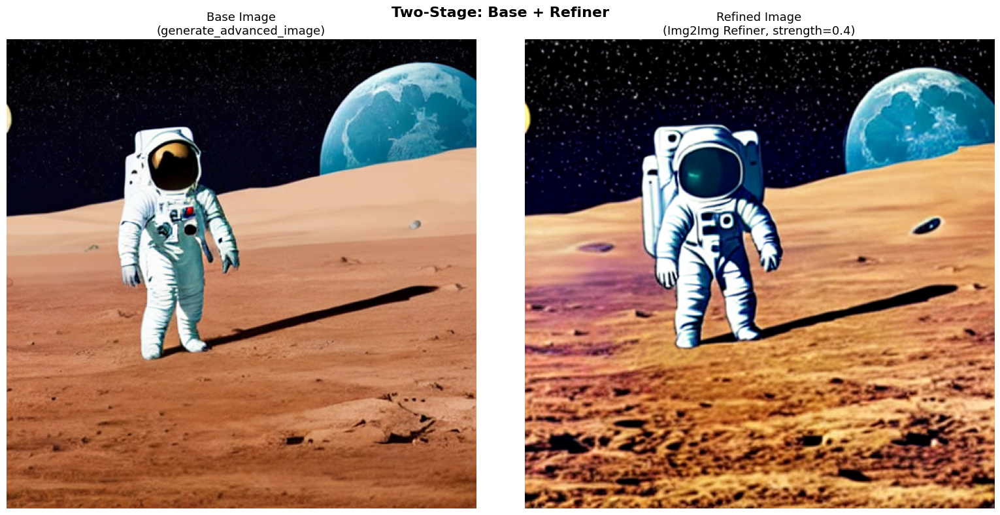

Refined image ready for inpainting!


In [9]:
from diffusers import StableDiffusionImg2ImgPipeline

# Load Img2Img pipeline (refiner) — menggunakan model yang sama
pipe_img2img = StableDiffusionImg2ImgPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
    safety_checker=None,
).to(device)

base_image = advanced_image  # hasil dari generate_advanced_image()

prompt = "an astronaut standing on the moon surface, planet earth and stars visible in the background, digital illustration, flat 2d, highly detailed, soft natural lighting, vibrant colors"
negative_prompt = "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, bad art, ugly, sketch, grainy, unfinished, chromatic aberration"

# STAGE 1: Base pipeline — generate LATENT, berhenti di 80% proses denoising
generator = torch.Generator(device).manual_seed(222)

base_latents = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    generator=generator,
    guidance_scale=7.5,
    num_inference_steps=50,
    denoising_end=0.8,
    output_type="latent",
).images

# STAGE 2: Refiner (Img2Img) — lanjutkan dari 80% sampai selesai
generator = torch.Generator(device).manual_seed(222)

refined_image = pipe_img2img(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=base_latents,
    generator=generator,
    guidance_scale=7.5,
    num_inference_steps=50,
    denoising_start=0.8,
).images[0]
# Perbandingan Base vs Refined
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(base_image)
axes[0].set_title("Base Image\n(generate_advanced_image)", fontsize=13)
axes[0].axis("off")

axes[1].imshow(refined_image)
axes[1].set_title("Refined Image\n(Img2Img Refiner, strength=0.4)", fontsize=13)
axes[1].axis("off")

plt.suptitle("Two-Stage: Base + Refiner", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

print("Refined image ready for inpainting!")

## **Inpainting**

### **Load Model Inpainting**

In [10]:
# Load Stable Diffusion Inpainting model
pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=torch.float16,
    safety_checker=None,
).to(device)

print("Inpainting model loaded!")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_inpaint.StableDiffusionInpaintPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing netwo

Inpainting model loaded!


### **Manual Masking**

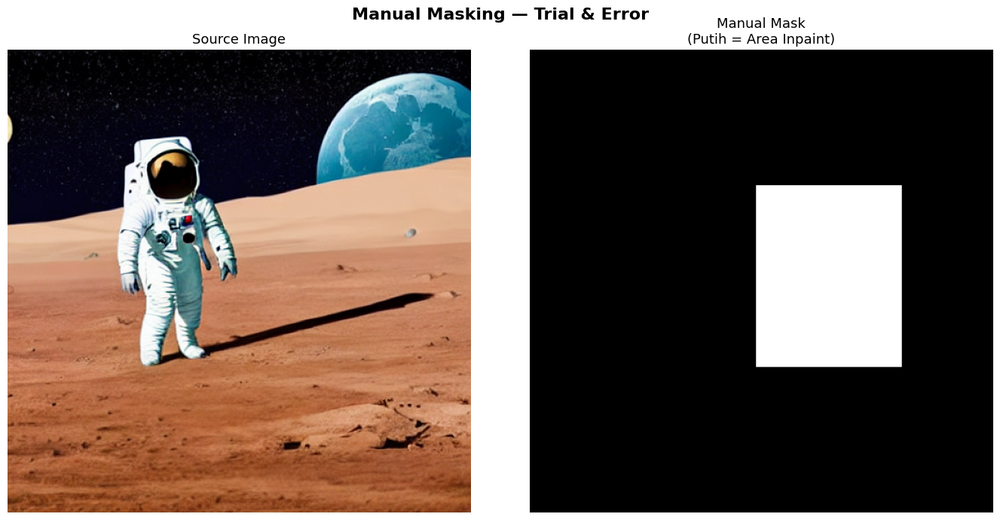

In [11]:
# Gunakan gambar hasil generate sebagai base image untuk inpainting
# (Pilih salah satu: advanced_image atau refined_image)
source_image = advanced_image.resize((512, 512))

# Buat mask manual — area putih = area yang akan di-inpaint
# Posisi mask: sebelah kanan astronot (trial and error)
mask = Image.new("L", source_image.size, 0)  # Hitam = keep
draw = ImageDraw.Draw(mask)

# Area beside astronaut for the broken satellite (adjusted coordinates for better placement)
draw.rectangle([250, 150, 410, 350], fill=255)  # White = edit area

# Update inpainting prompt to explicitly mention satellite location relative to astronaut
inpaint_prompt = (
    "a damaged orbital communication satellite resting on the lunar surface, "
    "clearly recognizable artificial satellite, "
    "compact metallic satellite body in the center, "
    "two long rectangular broken solar panels extending horizontally "
    "from the left and right sides, "
    "a visible parabolic dish antenna, small antennas, exposed cables, "
    "damaged electronic components and scattered metallic debris, "
    "partially buried in lunar dust, realistic scale, "
    "photorealistic, highly detailed, sharp focus, cinematic lighting"
)

negative_prompt = (
    "astronaut, human, person, lunar lander, moon lander, landing module, "
    "landing legs, rover, rocket, airplane, spacecraft cabin, building, "
    "vertical solar panels, only solar panels, wall, fence, rock pile, "
    "cartoon, drawing, painting, blurry, low quality, distorted, text, watermark"
)

# Tampilkan source image dan mask
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(source_image)
axes[0].set_title("Source Image", fontsize=13)
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Manual Mask\n(Putih = Area Inpaint)", fontsize=13)
axes[1].axis("off")

plt.suptitle("Manual Masking — Trial & Error", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### **Generate**

  0%|          | 0/57 [00:00<?, ?it/s]

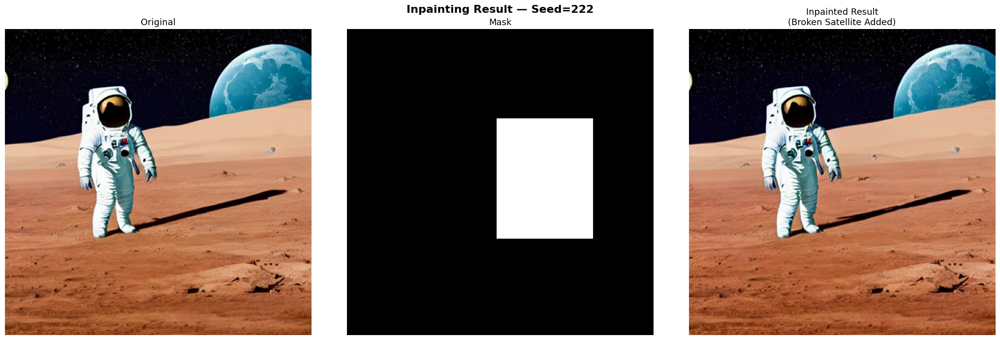

In [12]:
def inpaint_engine(image, mask, prompt, negative_prompt="grey color, shadow, smooth ground, empty moon surface, blurry, low resolution, bad anatomy, text, watermarks, photorealistic, 3d render", strength=1.0, seed=9):
    generator = torch.Generator(device).manual_seed(seed)

    if image.mode != "RGB":
        image = image.convert("RGB")
    if mask.mode != "L":
        mask = mask.convert("L")
    if image.size != mask.size:
        mask = mask.resize(image.size, resample=Image.NEAREST)

    result = pipe_inpaint(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=image,
        mask_image=mask,
        generator=generator,
        guidance_scale = 10.5,
        num_inference_steps = 60,
        strength=strength,
    ).images[0]

    return result

prompt_satellite = (
    "photorealistic NASA moon mission, white astronaut standing beside a compact "
    "lunar probe, shiny silver reflective solar panels, gold instrument module, "
    "small antenna dish, on dusty brown moon surface with small rocks, "
    "Earth rising in the background, black sky full of stars, "
    "realistic space exploration, ultra detailed, 8k, sharp focus"
)

negative_prompt_satellite = ( "astronaut, human, rover, lunar lander, landing legs, rocket, "
                             "destroyed satellite, exploded, heavy damage, missing parts, "
                              "cartoon, blurry, painting, low quality, distorted" )

inpainted_image = inpaint_engine(
    image=source_image,
    mask=mask,
    prompt=prompt_satellite,
    negative_prompt=negative_prompt_satellite,
    strength = 0.95,
    seed = 34
)

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
axes[0].imshow(source_image)
axes[0].set_title("Original", fontsize=13)
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Mask", fontsize=13)
axes[1].axis("off")

axes[2].imshow(inpainted_image)
axes[2].set_title("Inpainted Result\n(Broken Satellite Added)", fontsize=13)
axes[2].axis("off")

plt.suptitle(f"Inpainting Result — Seed={seed}", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

## **Inpainting Menggunakan Automasking**

### **load Model Segmentation Untuk Masking**

In [13]:
from transformers import SamModel, SamProcessor

# Load SAM (Segment Anything Model) dari HuggingFace
sam_model = SamModel.from_pretrained("facebook/sam-vit-base").to(device)
sam_processor = SamProcessor.from_pretrained("facebook/sam-vit-base")

print("SAM model loaded!")

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

SAM model loaded!


### **Masking with Segmentation Model**

Loading weights:   0%|          | 0/462 [00:00<?, ?it/s]

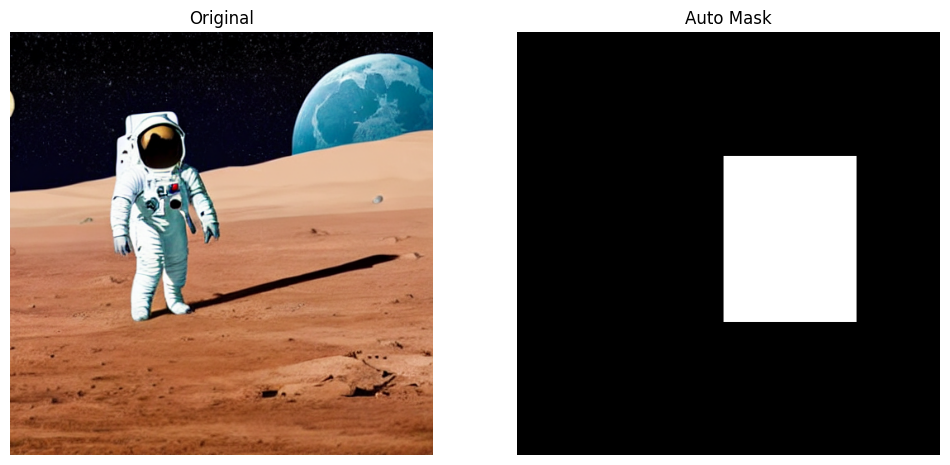

In [22]:
import numpy as np
import torch
from PIL import Image, ImageDraw
from transformers import CLIPSegProcessor, CLIPSegForImageSegmentation

# ======================================================
# Load CLIPSeg
# ======================================================
processor = CLIPSegProcessor.from_pretrained(
    "CIDAS/clipseg-rd64-refined"
)

clipseg = CLIPSegForImageSegmentation.from_pretrained(
    "CIDAS/clipseg-rd64-refined"
).to(device)

# ======================================================
# Auto Mask Function
# ======================================================
def create_mask_next_to_astronaut(
    image,
    offset=20,
    mask_width=170,
    mask_height=200,
    threshold=0.35,
):
    """
    Membuat mask di sebelah kanan astronaut menggunakan
    bounding box hasil segmentasi CLIPSeg.
    """

    if image.mode != "RGB":
        image = image.convert("RGB")

    width, height = image.size

    # -----------------------------
    # Segment astronaut
    # -----------------------------
    inputs = processor(
        text=["astronaut"],
        images=[image],
        padding=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = clipseg(**inputs)

    pred = torch.sigmoid(outputs.logits)[0]

    pred = pred.cpu().numpy()

    # Resize ke ukuran gambar asli
    pred = Image.fromarray((pred * 255).astype(np.uint8))
    pred = pred.resize((width, height))

    pred = np.array(pred) / 255.0

    # Binary mask astronaut
    astronaut_mask = pred > threshold

    # ==================================================
    # Cari bounding box astronaut
    # ==================================================
    ys, xs = np.where(astronaut_mask)

    if len(xs) == 0 or len(ys) == 0:
        raise ValueError("Astronaut tidak terdeteksi.")

    x1 = xs.min()
    x2 = xs.max()
    y1 = ys.min()
    y2 = ys.max()

    # ==================================================
    # Buat mask baru di samping astronaut
    # ==================================================
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)

    mask_x1 = x2 + offset
    mask_y1 = y1 + 20

    mask_x2 = mask_x1 + mask_width
    mask_y2 = mask_y1 + mask_height

    # Jangan keluar gambar
    mask_x2 = min(mask_x2, width - 1)
    mask_y2 = min(mask_y2, height - 1)

    draw.rectangle(
        [mask_x1, mask_y1, mask_x2, mask_y2],
        fill=255
    )

fig, ax = plt.subplots(1,2, figsize=(12,6))

ax[0].imshow(source_image)
ax[0].set_title("Original")
ax[0].axis("off")

ax[1].imshow(mask, cmap="gray")
ax[1].set_title("Auto Mask")
ax[1].axis("off")

plt.show()

### **Generate**

In [23]:
  auto_mask = create_mask_next_to_astronaut(
    image=source_image,
    offset=25,
    mask_width=160,
    mask_height=200,
    threshold=0.30
  )

  prompt_satellite = (
      "photorealistic NASA moon mission, white astronaut standing beside a compact "
      "lunar probe, shiny silver reflective solar panels, gold instrument module, "
      "small antenna dish, on dusty brown moon surface with small rocks, "
      "Earth rising in the background, black sky full of stars, "
      "realistic space exploration, ultra detailed, 8k, sharp focus"
  )

  negative_prompt_satellite = (
      "communication satellite, satellite orbiting, rover, lunar module, apollo lander, "
      "space station, rocket engine, destroyed probe, heavy damage, "
      "cartoon, anime, drawing, oil painting, sketch, toy, miniature, "
      "blurry, low quality, low resolution, bad proportions, duplicate, "
      "text, watermark, logo"
  )
  seed = 9

  # Inpainting menggunakan auto mask dari SAM
  auto_inpainted_image = inpaint_engine(
      source_image, auto_mask, prompt_satellite,
      negative_prompt=negative_prompt_satellite,
      seed=seed
  )

  # Perbandingan Manual Mask vs Auto Mask inpainting
  fig, axes = plt.subplots(1, 3, figsize=(21, 7))

  axes[0].imshow(source_image)
  axes[0].set_title("Original", fontsize=13)
  axes[0].axis("off")

  axes[1].imshow(inpainted_image)
  axes[1].set_title("Inpainting — Manual Mask", fontsize=13)
  axes[1].axis("off")

  axes[2].imshow(auto_inpainted_image)
  axes[2].set_title("Inpainting — Auto Mask (SAM)", fontsize=13)
  axes[2].axis("off")

  plt.suptitle("Perbandingan Manual vs Automatic Masking", fontsize=16, fontweight="bold")
  plt.tight_layout()
  plt.show()

  # Inpainting menggunakan auto mask dari SAM
  auto_inpaint_prompt = "a broken satellite, shattered solar panels, visible intricate internal wires, metallic debris, mechanical parts, realistic space junk, cinematic lighting, dramatic shadows, extreme detail, 8k, photorealistic"

  auto_inpainted_image = inpaint_engine(source_image, auto_mask, auto_inpaint_prompt, seed=9)

  # Perbandingan Manual Mask vs Auto Mask inpainting
  fig, axes = plt.subplots(1, 3, figsize=(21, 7))

  axes[0].imshow(source_image)
  axes[0].set_title("Original", fontsize=13)
  axes[0].axis("off")

  axes[1].imshow(inpainted_image)
  axes[1].set_title("Inpainting — Manual Mask", fontsize=13)
  axes[1].axis("off")

  axes[2].imshow(auto_inpainted_image)
  axes[2].set_title("Inpainting — Auto Mask (SAM)", fontsize=13)
  axes[2].axis("off")

  plt.suptitle("Perbandingan Manual vs Automatic Masking", fontsize=16, fontweight="bold")
  plt.tight_layout()
  plt.show()

ValueError: Astronaut tidak terdeteksi.

## **Outpainting**

### **Prepare the Canvas**

In [ ]:
def prepare_outpainting(image, direction="right", expand_pixels=256):
    """
    Memperluas kanvas ke SATU arah untuk outpainting.

    Parameters:
        image: PIL Image — gambar sumber
        direction: str — arah perluasan ("left", "right", "up", "down")
        expand_pixels: int — jumlah piksel perluasan

    Returns:
        canvas: PIL Image — gambar dengan kanvas diperluas
        mask: PIL Image mode "L" — mask (putih = area baru)
    """
    w, h = image.size

    if direction == "right":
        new_w = w + expand_pixels
        new_h = h
        # Safety: kelipatan 8
        new_w -= (new_w % 8)
        new_h -= (new_h % 8)
        # Buat canvas dengan blur background
        canvas = Image.new("RGB", (new_w, new_h), (0, 0, 0))
        canvas.paste(image, (0, 0))
        # Blur area baru agar transisi halus
        bg = image.resize((new_w, new_h), resample=Image.BICUBIC)
        bg = bg.filter(ImageFilter.GaussianBlur(radius=30))
        canvas_bg = bg.copy()
        canvas_bg.paste(image, (0, 0))
        canvas = canvas_bg
        # Mask: putih di area baru (kanan)
        mask = Image.new("L", (new_w, new_h), 0)
        draw = ImageDraw.Draw(mask)
        draw.rectangle([w, 0, new_w, new_h], fill=255)

    elif direction == "left":
        new_w = w + expand_pixels
        new_h = h
        new_w -= (new_w % 8)
        new_h -= (new_h % 8)
        offset_x = new_w - w
        canvas = Image.new("RGB", (new_w, new_h), (0, 0, 0))
        bg = image.resize((new_w, new_h), resample=Image.BICUBIC)
        bg = bg.filter(ImageFilter.GaussianBlur(radius=30))
        canvas = bg.copy()
        canvas.paste(image, (offset_x, 0))
        mask = Image.new("L", (new_w, new_h), 0)
        draw = ImageDraw.Draw(mask)
        draw.rectangle([0, 0, offset_x, new_h], fill=255)

    elif direction == "down":
        new_w = w
        new_h = h + expand_pixels
        new_w -= (new_w % 8)
        new_h -= (new_h % 8)
        canvas = Image.new("RGB", (new_w, new_h), (0, 0, 0))
        bg = image.resize((new_w, new_h), resample=Image.BICUBIC)
        bg = bg.filter(ImageFilter.GaussianBlur(radius=30))
        canvas = bg.copy()
        canvas.paste(image, (0, 0))
        mask = Image.new("L", (new_w, new_h), 0)
        draw = ImageDraw.Draw(mask)
        draw.rectangle([0, h, new_w, new_h], fill=255)

    elif direction == "up":
        new_w = w
        new_h = h + expand_pixels
        new_w -= (new_w % 8)
        new_h -= (new_h % 8)
        offset_y = new_h - h
        canvas = Image.new("RGB", (new_w, new_h), (0, 0, 0))
        bg = image.resize((new_w, new_h), resample=Image.BICUBIC)
        bg = bg.filter(ImageFilter.GaussianBlur(radius=30))
        canvas = bg.copy()
        canvas.paste(image, (0, offset_y))
        mask = Image.new("L", (new_w, new_h), 0)
        draw = ImageDraw.Draw(mask)
        draw.rectangle([0, 0, new_w, offset_y], fill=255)

    return canvas, mask


# Outpainting ke kanan — menggunakan gambar hasil inpainting sebagai input
outpaint_canvas, outpaint_mask = prepare_outpainting(
    inpainted_image, direction="right", expand_pixels=256
)

# Tampilkan canvas dan mask
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(outpaint_canvas)
axes[0].set_title("Expanded Canvas (Right)", fontsize=13)
axes[0].axis("off")

axes[1].imshow(outpaint_mask, cmap="gray")
axes[1].set_title("Outpainting Mask\n(Putih = Area Baru)", fontsize=13)
axes[1].axis("off")

plt.suptitle("Prepare Outpainting — Direction: Right", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### **Generate**

In [ ]:
# Outpainting — generate konten di area yang diperluas
outpaint_prompt = "a wide view of an astronaut on the moon surface with a broken satellite, Earth in the background, moon landscape extending to the right, digital art, vibrant colors, highly detailed"

outpainted_image = inpaint_engine(outpaint_canvas, outpaint_mask, outpaint_prompt, seed=9)

# Tampilkan hasil outpainting
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

axes[0].imshow(inpainted_image)
axes[0].set_title("Input (Inpainted Image)", fontsize=13)
axes[0].axis("off")

axes[1].imshow(outpaint_canvas)
axes[1].set_title("Expanded Canvas + Blur BG", fontsize=13)
axes[1].axis("off")

axes[2].imshow(outpainted_image)
axes[2].set_title("Outpainting Result\n(Right Direction)", fontsize=13)
axes[2].axis("off")

plt.suptitle("Outpainting — Extend Right", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

## **Outpainting Zoom Out**

### **Prepare Canvas for Zoom Out**

In [ ]:
def prepare_zoom_out(image, expand_pixels=128):
    """
    Memperluas kanvas ke SEMUA arah (zoom out effect).
    Gambar asli ditempatkan di tengah, area baru di-mask.

    Parameters:
        image: PIL Image — gambar sumber
        expand_pixels: int — jumlah piksel perluasan per sisi

    Returns:
        canvas: PIL Image — gambar dengan kanvas diperluas
        mask: PIL Image mode "L" — mask (putih = area baru, hitam = keep)
    """
    w, h = image.size
    new_w = w + (expand_pixels * 2)
    new_h = h + (expand_pixels * 2)

    # Safety: resolusi kelipatan 8
    new_w -= (new_w % 8)
    new_h -= (new_h % 8)

    # Background blur
    bg = image.resize((new_w, new_h), resample=Image.BICUBIC)
    bg = bg.filter(ImageFilter.GaussianBlur(radius=50))

    # Paste gambar asli di tengah
    canvas = bg.copy()
    paste_x = (new_w - w) // 2
    paste_y = (new_h - h) // 2
    canvas.paste(image, (paste_x, paste_y))

    # Mask: putih = area baru (edit), hitam = area asli (keep)
    mask = Image.new("L", (new_w, new_h), 255)
    inner_box = Image.new("L", (w, h), 0)
    mask.paste(inner_box, (paste_x, paste_y))

    return canvas, mask


# Zoom Out — menggunakan gambar hasil outpainting sebagai input
zoom_canvas, zoom_mask = prepare_zoom_out(outpainted_image, expand_pixels=128)

# Tampilkan canvas dan mask
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(zoom_canvas)
axes[0].set_title("Zoom Out Canvas", fontsize=13)
axes[0].axis("off")

axes[1].imshow(zoom_mask, cmap="gray")
axes[1].set_title("Zoom Out Mask\n(Putih = Area Baru)", fontsize=13)
axes[1].axis("off")

plt.suptitle("Prepare Zoom Out — All Directions", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### **Generate**

In [ ]:
# Zoom Out — generate konten di area yang diperluas ke semua arah
zoom_prompt = "a wide panoramic view of an astronaut on the moon surface with a broken satellite, Earth in the sky, vast moon landscape, craters, stars, digital art, vibrant colors, highly detailed, 8k"

zoom_result = inpaint_engine(zoom_canvas, zoom_mask, zoom_prompt, seed=9)

# Tampilkan hasil Zoom Out
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(outpainted_image)
axes[0].set_title("Before Zoom Out", fontsize=13)
axes[0].axis("off")

axes[1].imshow(zoom_result)
axes[1].set_title("After Zoom Out\n(All Directions Expanded)", fontsize=13)
axes[1].axis("off")

plt.suptitle("Outpainting Zoom Out Result", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()